In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Load Dataset

df = pd.read_csv("sales_data_sample.csv", encoding="ISO-8859-1")

print("First 5 records:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)


First 5 records:
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abb

In [3]:
# 2. Select Numerical Features

# We use sales-related numerical attributes
features = [
    "QUANTITYORDERED",
    "PRICEEACH",
    "SALES"
]

X = df[features]

# Check for missing values
print("\nMissing values:")
print(X.isnull().sum())



Missing values:
QUANTITYORDERED    0
PRICEEACH          0
SALES              0
dtype: int64


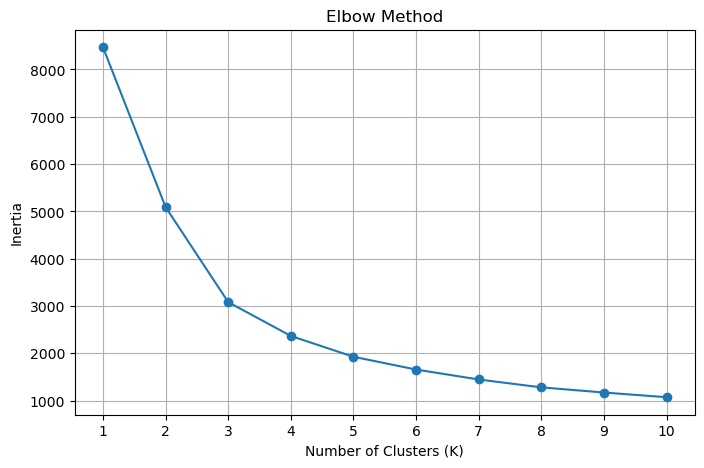

In [4]:
# 3. Standardize the Data

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Elbow Method

inertia = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Plot Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [5]:
# 5. Apply K-Means

# Select K based on the elbow point
k = 3

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

# 6. Display Cluster Information

print("\nCluster Counts:")
print(df["Cluster"].value_counts().sort_index())

print("\nCluster Centers:")
centers = scaler.inverse_transform(kmeans.cluster_centers_)

cluster_centers = pd.DataFrame(
    centers,
    columns=features
)

print(cluster_centers)




Cluster Counts:
Cluster
0     881
1     907
2    1035
Name: count, dtype: int64

Cluster Centers:
   QUANTITYORDERED  PRICEEACH        SALES
0        35.125993  57.130216  2009.829955
1        43.843612  96.623910  5581.559273
2        27.380077  94.876054  3088.890561



Clustered Data:
    QUANTITYORDERED  PRICEEACH    SALES  Cluster
0                30      95.70  2871.00        2
1                34      81.35  2765.90        2
2                41      94.74  3884.34        1
3                45      83.26  3746.70        1
4                49     100.00  5205.27        1
5                36      96.66  3479.76        2
6                29      86.13  2497.77        2
7                48     100.00  5512.32        1
8                22      98.57  2168.54        2
9                41     100.00  4708.44        1
10               37     100.00  3965.66        2
11               23     100.00  2333.12        2
12               28     100.00  3188.64        2
13               34     100.00  3676.76        2
14               45      92.83  4177.35        1
15               36     100.00  4099.68        2
16               23     100.00  2597.39        2
17               41     100.00  4394.38        1
18               46      94.74  4358.04        1
19 

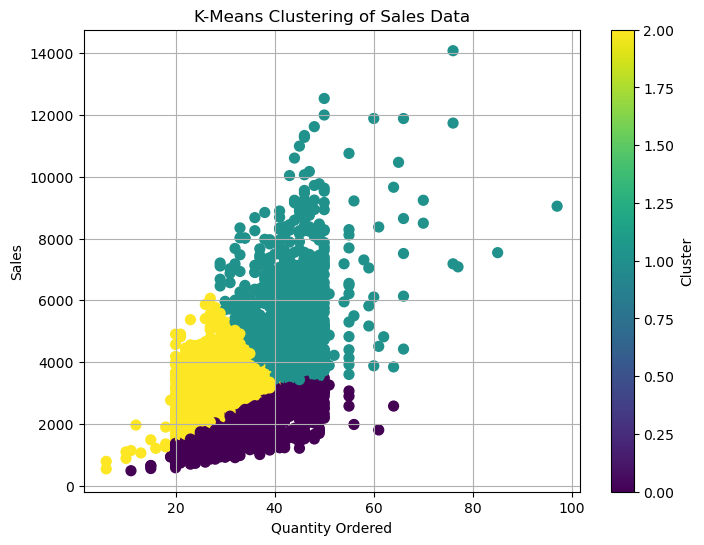

In [6]:
# 7. Display Sample Clustered Data

print("\nClustered Data:")
print(df[features + ["Cluster"]].head(20))

# 8. Visualize Clusters

plt.figure(figsize=(8, 6))

plt.scatter(
    df["QUANTITYORDERED"],
    df["SALES"],
    c=df["Cluster"],
    cmap="viridis",
    s=50
)

plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.title("K-Means Clustering of Sales Data")
plt.colorbar(label="Cluster")
plt.grid(True)
plt.show()